In [1]:
import librosa
from IPython.display import HTML  # this is for displaying metadata about the example
import matplotlib.pyplot as plt
import numpy as np
import torch
from whisper.audio import load_audio, pad_or_trim, N_SAMPLES, log_mel_spectrogram
import whisper
#from documentation

In [ ]:
path = "/Users/medurarvind/pdhc/data/hc/AVPEPUDEAC0001_a.wav"
filename = "AVPEPUDEAC0001_a.wav"
audio, sr = librosa.load(path, sr=16000)
print(audio,sr)
print("number of samples: ", audio.shape)
print("duration (s): ", audio.shape[0] / sr)

# And print out some information about this example
#setting of sampling rate: sr=None or sr = 160000

In [ ]:
fig,ax=plt.subplots()
librosa.display.waveshow(audio,sr=sr,ax=ax)
ax.set(title=f"Plot of the audio file : {filename}")

In [ ]:
audio_dft=np.fft.fft(audio)
frequencies = np.fft.fftfreq(len(audio), d=1 / sr)

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(frequencies, np.abs(audio_dft), color="C1")
ax.set(title="Frequency domain representation",
          xlabel="Frequency (Hz)",
          ylabel="Magnitude")

In [ ]:
#instead use the rfft:
audio_dft=np.fft.rfft(audio)
frequencies = np.fft.rfftfreq(len(audio), d=1 / sr)
fig, ax = plt.subplots()
ax.plot(frequencies, np.abs(audio_dft), color="C1")
ax.set(title="Frequency domain representation",
          xlabel="Frequency (Hz)",
          ylabel="Magnitude")

In [ ]:
stft = librosa.stft(audio)

In [ ]:
fig, ax = plt.subplots(nrows=2, sharex=True)
img = librosa.display.specshow(stft, vscale="dBFS",
                               sr=sr, hop_length=512, x_axis="time", y_axis="hz", ax=ax[0])
librosa.display.colorbar_db(img, label="dBFS")
ax[0].set(title="Spectrogram")
ax[0].label_outer()
librosa.display.waveshow(audio, sr=sr, ax=ax[1])
ax[1].set(title="Time-domain")

In [ ]:
import os

hc_dir = "/Users/medurarvind/pdhc/data/hc"
pd_dir = "/Users/medurarvind/pdhc/data/pd"

hc_files = [f for f in os.listdir(hc_dir) if f.endswith(".wav")]
pd_files = [f for f in os.listdir(pd_dir) if f.endswith(".wav")]

print(f"HC files: {len(hc_files)}")
print(f"PD files: {len(pd_files)}")
print(f"Total: {len(hc_files) + len(pd_files)}")

In [ ]:
#DOCS
# pad_or_trim(
#     array: Union[np.ndarray, torch.Tensor],
#     length: int = N_SAMPLES,
#     *,
#     axis: int = -1
# ) -> Union[np.ndarray, torch.Tensor]
audio = pad_or_trim(audio)
print(audio.shape) 
print(audio.shape[0] / sr)

In [ ]:
#DOCS
# log_mel_spectrogram(
#     audio: Union[str, np.ndarray, torch.Tensor],
#     n_mels: int = 80,
#     padding: int = 0,
#     device: Optional[Union[str, torch.device]] = None
# ) -> torch.Tensor
me1=log_mel_spectrogram(audio) #thats a torch tensor
print(me1.shape) 
me1 = me1.unsqueeze(0) 
#since we have a 2d sensor, we are unsqueezing and adding a new dimension
print(me1.shape)

In [ ]:
def feature_extractor(filepath):
    #input as .wav path and thats being converted to the audio file at 16k sampling freq.
    audio, sr = librosa.load(filepath, sr=16000)
    #initsize=(audio.shape[0]/sr) 
    audio=whisper.pad_or_trim(audio)
    #print(f"initial size of audio: {initsize} \n current size of audio: {audio.shape[0]/sr}")
    #get the spectrogram of the audio file
    logmel=whisper.log_mel_spectrogram(audio)
    #initdim=logmel.shape
    logmel=logmel.unsqueeze(0)
    #print(f"size of spectrogram before unsqueezing: {initdim} \n after unsqueezing: {logmel.shape}")
    audio_features = model.embed_audio(logmel)
    pooled_feature=torch.mean(audio_features,dim=1)
    #print(f" the audio features file has {audio_features.shape[0]} batches, {audio_features.shape[1]} frequency bins and the time frames is {audio_features.shape[-1]}")
    #print(f" the pooled features file has {pooled_feature.shape[0]} batches, {pooled_feature.shape[-1]} feature dimensions")
    #final feature extracted tensor for that specific .wav
    #return statement:
    return pooled_feature.detach().cpu().numpy().flatten()

In [ ]:
audio_features = model.embed_audio(me1)
print(audio_features.shape)

In [ ]:
pooled_features = torch.mean(audio_features, dim=1)
print(pooled_features.shape)

# THIS IS THE FUNCTION FOR CARRYING OUT FEATURE EXTRACTION FOR A .WAV FILE
### workflow:
- first load the audio file using librosa.load, resample to 16k
- pad the audio clip to a 30s duration
- get the log mel spectrogram and unsqueeze to 3 dimensions
- start with the small model of whisper and then get the audio features
- lastly pool the features to form a tensor of size [1,768]

In [15]:
import librosa
from IPython.display import HTML  # this is for displaying metadata about the example
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from whisper.audio import load_audio, pad_or_trim, N_SAMPLES, log_mel_spectrogram
import whisper
#from documentation

In [22]:
model = whisper.load_model("small")
# tiny does 384, base does 512 and small does 768

In [ ]:
def feature_extractor(filepath):
    audio, sr = librosa.load(filepath, sr=16000)
    audio=whisper.pad_or_trim(audio)
    logmel=whisper.log_mel_spectrogram(audio)
    logmel=logmel.unsqueeze(0)
    audio_features = model.embed_audio(logmel)
    pooled_feature=torch.mean(audio_features,dim=1)
    return pooled_feature.detach().cpu().numpy().flatten()

In [ ]:
# ============================================================
# SPEAKER SPLIT
# ============================================================

PD_TEST_SPEAKERS = {
    "AVPEPUDEA0002",
    "AVPEPUDEA0007",
    "AVPEPUDEA0008",
    "AVPEPUDEA0009",
    "AVPEPUDEA0010",
    "AVPEPUDEA0017",
    "AVPEPUDEA0020",
    "AVPEPUDEA0022",
    "AVPEPUDEA0043",
    "AVPEPUDEA0050",
}

PD_TRAIN_SPEAKERS = {
    "AVPEPUDEA0001",
    "AVPEPUDEA0003",
    "AVPEPUDEA0005",
    "AVPEPUDEA0006",
    "AVPEPUDEA0011",
    "AVPEPUDEA0013",
    "AVPEPUDEA0014",
    "AVPEPUDEA0015",
    "AVPEPUDEA0016",
    "AVPEPUDEA0021",
    "AVPEPUDEA0023",
    "AVPEPUDEA0024",
    "AVPEPUDEA0025",
    "AVPEPUDEA0026",
    "AVPEPUDEA0027",
    "AVPEPUDEA0029",
    "AVPEPUDEA0030",
    "AVPEPUDEA0031",
    "AVPEPUDEA0032",
    "AVPEPUDEA0034",
    "AVPEPUDEA0035",
    "AVPEPUDEA0037",
    "AVPEPUDEA0038",
    "AVPEPUDEA0039",
    "AVPEPUDEA0041",
    "AVPEPUDEA0042",
    "AVPEPUDEA0045",
    "AVPEPUDEA0046",
    "AVPEPUDEA0047",
    "AVPEPUDEA0048",
    "AVPEPUDEA0049",
    "AVPEPUDEA0051",
    "AVPEPUDEA0052",
    "AVPEPUDEA0053",
    "AVPEPUDEA0054",
    "AVPEPUDEA0055",
    "AVPEPUDEA0056",
    "AVPEPUDEA0057",
    "AVPEPUDEA0058",
    "AVPEPUDEA0059",
}

HC_TEST_SPEAKERS = {
    "AVPEPUDEAC0003",
    "AVPEPUDEAC0007",
    "AVPEPUDEAC0008",
    "AVPEPUDEAC0010",
    "AVPEPUDEAC0011",
    "AVPEPUDEAC0017",
    "AVPEPUDEAC0018",
    "AVPEPUDEAC0020",
    "AVPEPUDEAC0040",
    "AVPEPUDEAC0046",
}

HC_TRAIN_SPEAKERS = {
    "AVPEPUDEAC0001",
    "AVPEPUDEAC0004",
    "AVPEPUDEAC0005",
    "AVPEPUDEAC0006",
    "AVPEPUDEAC0012",
    "AVPEPUDEAC0013",
    "AVPEPUDEAC0014",
    "AVPEPUDEAC0015",
    "AVPEPUDEAC0016",
    "AVPEPUDEAC0019",
    "AVPEPUDEAC0021",
    "AVPEPUDEAC0022",
    "AVPEPUDEAC0023",
    "AVPEPUDEAC0024",
    "AVPEPUDEAC0025",
    "AVPEPUDEAC0026",
    "AVPEPUDEAC0027",
    "AVPEPUDEAC0028",
    "AVPEPUDEAC0029",
    "AVPEPUDEAC0030",
    "AVPEPUDEAC0031",
    "AVPEPUDEAC0033",
    "AVPEPUDEAC0034",
    "AVPEPUDEAC0035",
    "AVPEPUDEAC0037",
    "AVPEPUDEAC0039",
    "AVPEPUDEAC0041",
    "AVPEPUDEAC0042",
    "AVPEPUDEAC0043",
    "AVPEPUDEAC0044",
    "AVPEPUDEAC0045",
    "AVPEPUDEAC0047",
    "AVPEPUDEAC0048",
    "AVPEPUDEAC0049",
    "AVPEPUDEAC0050",
    "AVPEPUDEAC0051",
    "AVPEPUDEAC0052",
    "AVPEPUDEAC0053",
    "AVPEPUDEAC0054",
    "AVPEPUDEAC0057",
}
#speaker splitting for the train-test split got from ma'am

In [25]:
import os
from os.path import join, getsize
hcfiles,hctestfiles,hctrainfiles=[],[],[]
pdfiles,pdtestfiles,pdtrainfiles=[],[],[]
for root, dirs, files in os.walk("/Users/medurarvind/pdhc/data/hc/"):
    for f in files:
        if f.endswith(".wav"):
            full_path = os.path.join(root, f)
            hcfiles.append(os.path.join(root,f))
            if(f[:14] in HC_TEST_SPEAKERS ):
                hctestfiles.append(full_path)
                #temparr1.append(f[:14])
            if(f[:14] in HC_TRAIN_SPEAKERS ):
                hctrainfiles.append(full_path)   
                #temparr2.append(f[:14])
for root, dirs, files in os.walk("/Users/medurarvind/pdhc/data/pd/"):
    for f in files:
        if f.endswith(".wav"):
            full_path = os.path.join(root, f)
            pdfiles.append(os.path.join(root,f))
            if(f[:13] in PD_TEST_SPEAKERS ):
                pdtestfiles.append(full_path)
                #temparr3.append(f[:13])
            if(f[:13] in PD_TRAIN_SPEAKERS ):
                pdtrainfiles.append(full_path) 
                #temparr4.append(f[:13])


In [26]:
def process_to_list(filepath, label, split): #the label will give 0 for hc and 1 for pd
    for path in filepath:
        features=feature_extractor(path) 
        fname = os.path.basename(path)
        speakerid = fname[:14] if label == 0 else fname[:13]
        row = [speakerid, label, split] + features.tolist()
        dataset_rows.append(row)

In [ ]:
dataset_rows = []
process_to_list(hctrainfiles, 0, 'train')
process_to_list(hctestfiles, 0, 'test')
process_to_list(pdtrainfiles, 1, 'train')
process_to_list(pdtestfiles, 1, 'test')
column_names = ['speaker_id', 'label', 'split'] + [f'feat_{i}' for i in range(768)]
df = pd.DataFrame(dataset_rows, columns=column_names)
df.to_csv("whisper_parkinsons_features.csv", index=False)

In [28]:
df=pd.read_csv("whisper_parkinsons_features.csv")
df.head()

,speaker_id,label,split,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,...,feat_758,feat_759,feat_760,feat_761,feat_762,feat_763,feat_764,feat_765,feat_766,feat_767
0,AVPEPUDEAC0025,0,train,0.122634,0.116147,0.035268,0.224149,0.099441,-0.209959,0.205860,...,-0.340382,0.087220,-0.685684,0.424603,0.090099,0.159565,0.325854,-0.229523,-0.055460,-0.377120
1,AVPEPUDEAC0037,0,train,0.069927,0.152911,-0.045744,0.277996,0.159433,-0.020839,0.271709,...,-0.335547,0.069234,-0.444235,0.476856,0.220105,0.279774,0.372910,-0.003535,0.057552,-0.219493
2,AVPEPUDEAC0033,0,train,-0.002286,0.128401,-0.180310,0.221437,0.009820,-0.182397,0.230840,...,-0.338375,0.030059,-0.514367,0.362700,0.050177,0.121928,0.182255,-0.080269,-0.108667,-0.395301
3,AVPEPUDEAC0035,0,train,0.087899,0.235384,-0.019843,0.090091,0.135167,-0.017465,0.180754,...,-0.336025,0.000032,-0.490527,0.604503,0.147077,0.295885,0.466909,-0.094281,-0.028961,-0.395019
4,AVPEPUDEAC0034,0,train,0.085661,0.361515,-0.074729,0.173643,0.304807,0.028679,0.160863,...,-0.326873,-0.142499,-0.807092,0.572282,0.238467,0.422379,0.279747,-0.199850,0.062863,-0.400344


In [29]:
train_df = df[df['split'] == 'train']
test_df = df[df['split'] == 'test']


X_train = train_df.drop(['speaker_id', 'label', 'split'], axis=1)
y_train = train_df['label']

X_test = test_df.drop(['speaker_id', 'label', 'split'], axis=1)
y_test = test_df['label']

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

model = SVC(kernel='rbf', gamma='scale', C=1.0)

model.fit(X_train_scaled, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [34]:
y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7307692307692307

Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.70      0.72       520
           1       0.72      0.76      0.74       520

    accuracy                           0.73      1040
   macro avg       0.73      0.73      0.73      1040
weighted avg       0.73      0.73      0.73      1040



In [35]:
# Add your predictions to your test dataframe
test_df['predictions'] = y_pred

# Group by speaker_id and average the predictions
# Since 1 is PD and 0 is HC, an average > 0.5 means the majority of clips were PD
speaker_final = test_df.groupby('speaker_id').agg({
    'predictions': 'mean',
    'label': 'first' # The true label
})

# Convert average to a binary 0 or 1
speaker_final['final_diagnosis'] = (speaker_final['predictions'] > 0.5).astype(int)

from sklearn.metrics import accuracy_score
print("Final Speaker-Level Accuracy:", accuracy_score(speaker_final['label'], speaker_final['final_diagnosis']))

Final Speaker-Level Accuracy: 0.95


/var/folders/18/jndj0qhj0rjc2vv0dkqlxd680000gn/T/ipykernel_48449/9742291.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test_df['predictions'] = y_pred


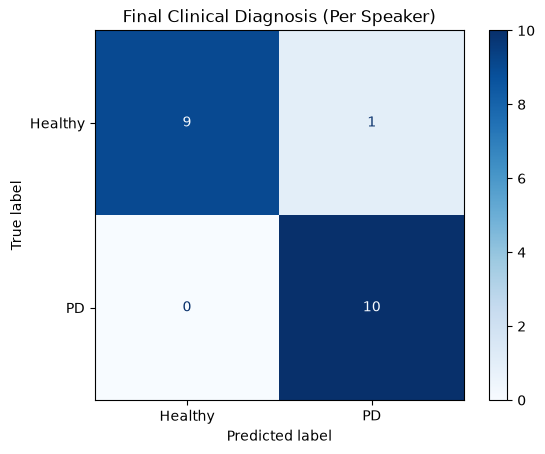

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use the speaker_final dataframe we made earlier
cm = confusion_matrix(speaker_final['label'], speaker_final['final_diagnosis'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Healthy', 'PD'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Final Clinical Diagnosis (Per Speaker)")
plt.show()